# TA-06 Pemodelan dan Simulasi - Pendinginan Secangkir Kopi
Model ODE orde 1 (Hukum Pendinginan Newton + pemanas):

$$\frac{dT}{dt} = -k\,(T - T_{env}) + g\,u(t)$$

- T: suhu kopi (state & controlled variable)
- T_env: suhu ruangan (input konstanta / gangguan)
- k: konstanta pendinginan, g: gain pemanas
- u(t): daya pemanas (%), sinyal kontrol

## 1-3. Parameter, model ODE, dan integrasi Euler

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ===== 1. PARAMETER MODEL =====
T0 = 90.0       # suhu awal kopi (C)
T_ENV = 30.0    # suhu ruangan (C) -> input konstanta
K = 0.05        # konstanta pendinginan (1/menit)
G = 0.02        # gain pemanas (C/menit per % daya)
DT = 1.0        # langkah waktu (menit)
T_END = 120.0   # lama simulasi (menit)

t = np.arange(0, T_END + DT, DT)   # deret waktu 0..120 menit

# ===== 2. MODEL ODE: dT/dt = -k (T - T_env) + g u =====
def dTdt(T, u, T_env=T_ENV):
    # suku 1: pendinginan Newton (umpan balik negatif)
    # suku 2: pemanasan dari pemanas (sinyal kontrol u)
    return -K * (T - T_env) + G * u

# ===== 3. INTEGRASI EULER =====
def simulate(t, u, T_init, T_env=None):
    if T_env is None:                  # default: suhu ruangan konstan
        T_env = np.full_like(t, T_ENV)
    T = np.zeros_like(t)
    T[0] = T_init                      # kondisi awal
    for i in range(1, len(t)):
        # T baru = T lama + laju perubahan x dt
        T[i] = T[i-1] + dTdt(T[i-1], u[i-1], T_env[i-1]) * DT
    return T

## Perhitungan manual (Euler, u = 0)

In [2]:
# Perhitungan manual Euler (u = 0), dt = 1 menit
print(f"{'t':>3} | {'T':>8} | {'T-Tenv':>8} | {'dT/dt':>8} | {'T(t+1)':>8}")
_T = T0
for i in range(6):
    d = dTdt(_T, 0.0)
    print(f"{i:>3} | {_T:8.4f} | {_T - T_ENV:8.4f} | {d:8.4f} | {_T + d * DT:8.4f}")
    _T = _T + d * DT

  t |        T |   T-Tenv |    dT/dt |   T(t+1)
  0 |  90.0000 |  60.0000 |  -3.0000 |  87.0000
  1 |  87.0000 |  57.0000 |  -2.8500 |  84.1500
  2 |  84.1500 |  54.1500 |  -2.7075 |  81.4425
  3 |  81.4425 |  51.4425 |  -2.5721 |  78.8704
  4 |  78.8704 |  48.8704 |  -2.4435 |  76.4269
  5 |  76.4269 |  46.4269 |  -2.3213 |  74.1055


## 4. Steady state (tanpa pemanas)

Suhu akhir (Euler): 30.13 C
Galat maks Euler vs eksak: 0.564 C


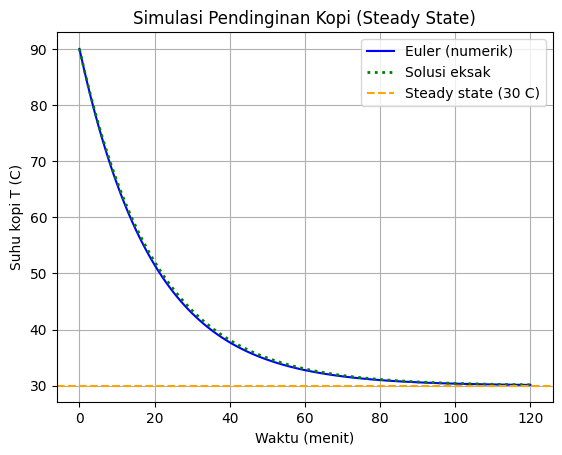

In [3]:
# ===== 4. STEADY STATE (tanpa pemanas, u = 0) =====
def analytic_cooling(t):
    # solusi eksak, dipakai sebagai pembanding galat Euler
    return T_ENV + (T0 - T_ENV) * np.exp(-K * t)

u0 = np.zeros_like(t)                  # pemanas mati
T_num = simulate(t, u0, T0)
T_eks = analytic_cooling(t)
print("Suhu akhir (Euler):", round(T_num[-1], 2), "C")
print("Galat maks Euler vs eksak:", round(np.max(np.abs(T_num - T_eks)), 3), "C")

plt.plot(t, T_num, "b", label="Euler (numerik)")
plt.plot(t, T_eks, "g:", lw=2, label="Solusi eksak")
plt.axhline(T_ENV, color="orange", ls="--", label="Steady state (30 C)")
plt.xlabel("Waktu (menit)")
plt.ylabel("Suhu kopi T (C)")
plt.title("Simulasi Pendinginan Kopi (Steady State)")
plt.legend()
plt.grid(True)
plt.show()

## 5. Respon terhadap sinyal kontrol pemanas
Kopi mulai dari suhu ruangan (30 C), lalu pemanas diberi sinyal step, impuls, ramp, dan sinusoida.

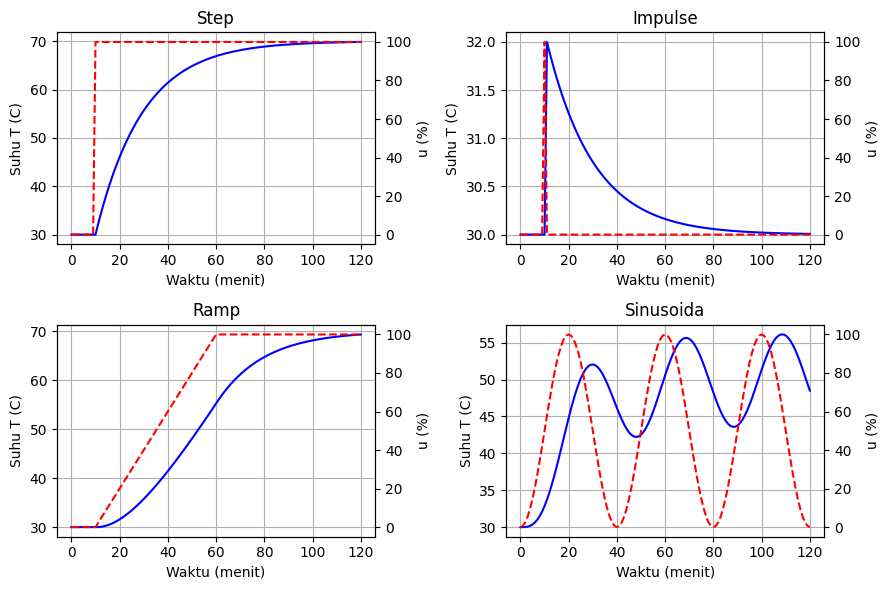

In [4]:
# ===== 5. RESPON TERHADAP SINYAL KONTROL u(t) (%) =====
def sig_step(t):    return np.where(t >= 10, 100.0, 0.0)      # naik mendadak, menetap
def sig_impulse(t): return np.where((t >= 10) & (t < 10 + DT), 100.0, 0.0)  # pulsa 1 menit
def sig_ramp(t):    return np.clip(2.0 * (t - 10), 0.0, 100.0)  # naik 2 %/menit
def sig_sine(t):    return 50.0 + 50.0 * np.sin(2*np.pi*t/40.0 - np.pi/2)  # periode 40 menit

scenarios = [("Step", sig_step), ("Impulse", sig_impulse),
             ("Ramp", sig_ramp), ("Sinusoida", sig_sine)]

fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, (nama, fungsi) in zip(axes.ravel(), scenarios):
    u = fungsi(t)
    T = simulate(t, u, T_ENV)          # kopi mulai dari suhu ruangan
    ax.plot(t, T, "b")
    ax.set_title(nama)
    ax.set_xlabel("Waktu (menit)")
    ax.set_ylabel("Suhu T (C)")
    ax.grid(True)
    ax2 = ax.twinx()                   # sumbu kanan: daya pemanas
    ax2.plot(t, u, "r--")
    ax2.set_ylabel("u (%)")
plt.tight_layout()
plt.show()

## 6. Gangguan: suhu ruangan berubah
Pemanas mati, suhu ruangan naik dari 30 C ke 40 C pada t = 30 menit.

Steady state baru (teori): 40.0 C
Suhu akhir gangguan (Euler): 39.9 C


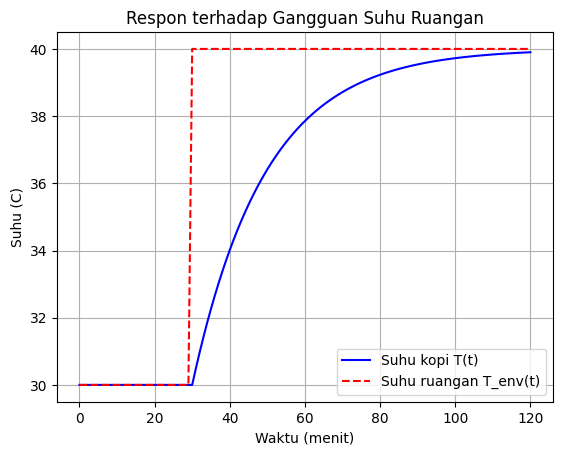

In [5]:
# ===== 6. GANGGUAN: SUHU RUANGAN BERUBAH =====
def env_disturbance(t):
    # ruangan naik dari 30 C ke 40 C pada t = 30 menit
    return np.where(t >= 30, 40.0, 30.0)

T_env_d = env_disturbance(t)
# pemanas mati (u = 0), kopi mulai dari 30 C (setimbang dengan ruangan)
T_dist = simulate(t, np.zeros_like(t), 30.0, T_env_d)
print("Steady state baru (teori):", 40.0, "C")
print("Suhu akhir gangguan (Euler):", round(T_dist[-1], 2), "C")

plt.plot(t, T_dist, "b", label="Suhu kopi T(t)")
plt.plot(t, T_env_d, "r--", label="Suhu ruangan T_env(t)")
plt.xlabel("Waktu (menit)")
plt.ylabel("Suhu (C)")
plt.title("Respon terhadap Gangguan Suhu Ruangan")
plt.legend()
plt.grid(True)
plt.show()